# Part 2 — Calibration by the method of moments (GMM)

**Question.** If the data come exactly from the model, can we recover its parameters from summary statistics (moments)?

**Method.** Pick statistics of the returns (volatility, autocorrelations…), then find the θ for which the model reproduces the observed statistics, by minimizing $D_W(\theta) = g^\top W g$ with $g = \hat c_{\text{obs}} - \hat c_{\text{model}}(\theta)$. The "data" are a series simulated at a known θ (`theta_active`): we know the right answer.

**Outline.**
1. **2.1** Choice of moments by sensitivity analysis: normalized Jacobian and SVD (which parameters are identifiable?).
2. **2.2** Objective function (E-GMM: 10 fixed-seed simulations), 1D and 2D cuts.
3. **2.3** Optimization: Nelder-Mead and DIRECT.
4. **2.4** Hansen's optimal weighting matrix and J-test.
5. **3.2** Speeding up the simulator with numba (×90), needed for what follows.
6. **2.5** Monte Carlo over 50 series: the real precision of the estimator.

**Requires** `abm.py`, `data/sp500_daily.csv`. Runtime: a few minutes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.optimize import minimize, direct

from abm import (theta0, theta_active, THETA_TRUE, ESTIMATED_PARAMS, chiarella, hill,
                 STAT_NAMES, stats, get_moments_2, compute_jacobian, gmm_objective,
                 hansen_matrix, estimate)

rng = np.random.default_rng(42)

## 2.1 Choice of moments and identifiability

The GMM compares **statistics** of the returns (the "moments") computed on the data and on the model. A statistic that does not move when θ changes cannot be used to estimate it. I start from 12 candidates (volatility, tails, skewness, autocorrelations of r and |r|), here on the S&P 500:

In [2]:
sp500 = pd.read_csv("../data/sp500_daily.csv", index_col="date", parse_dates=True)
r_sp = np.log(sp500["adj_close"]).diff().dropna()

pd.Series(stats(r_sp.values), index=STAT_NAMES)

std          0.010829
tail         2.846116
kurt        13.517920
skew        -0.606558
acf1        -0.111481
acf2         0.071365
acf3        -0.042241
acf5         0.005021
acfabs1      0.313474
acfabs5      0.294084
acfabs10     0.260358
acfabs20     0.165062
dtype: float64

**Tail exponent (Hill estimator).** About 3 on the S&P 500 (the "inverse cubic law"). On the near-Gaussian model at `theta0` it is much higher and has no power-law meaning; the Jacobian will show it barely reacts to the parameters.

In [3]:
p_test, _, _ = chiarella(**theta0, T=5000, rng=np.random.default_rng(0))
print("Hill, S&P 500:", hill(r_sp.values))
print("Hill, theta0 :", hill(np.diff(p_test)))

Hill, S&P 500: 2.846115635694452
Hill, theta0 : 6.314179108430747


**Sensitivity analysis: the normalized Jacobian.** Each parameter θ_j is moved by ±5 % and we measure how much each statistic moves:

$$J_{kj} = \frac{c_k(\theta_j + 5\,\%) - c_k(\theta_j - 5\,\%)}{2 \times \text{noise}_k}$$

- averaged over 20 simulations, with **the same seeds** on both sides, so the noise cancels in the difference;
- divided by the statistic's **noise** (its std across simulations): J ≈ 1 means a 5 % change is just detectable on one series.

I work at `theta_active` (κ = 50, λ = 0.01): at `theta0` the fundamentalists are invisible and the κ column would be zero.

In [4]:
# get_moments and compute_jacobian are defined in abm.py
seeds = range(42, 62)
J_norm = compute_jacobian(theta_active, seeds)

**Reading the heatmap.** A row near 0 is a useless statistic; a column near 0 is an invisible parameter. On the right, the **singular values** of J: each measures how much a *combination* of parameters moves the statistics (in noise standard deviations). ≳ 1: identifiable combination; ≪ 1: invisible.

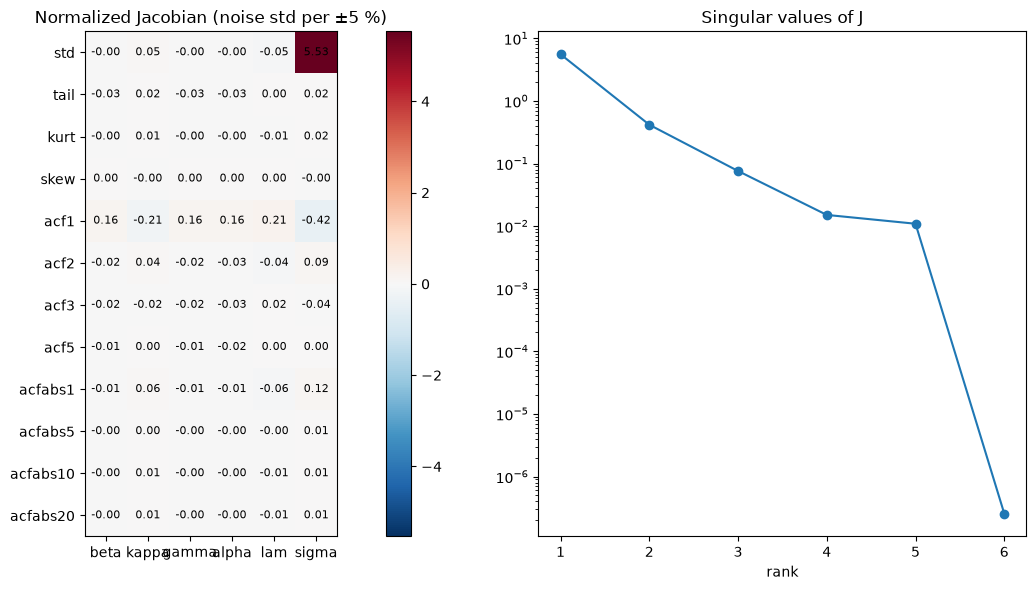

Condition number: 21647749.641182825


In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [2, 1]})

lim = np.abs(J_norm).max()
im = ax1.imshow(J_norm, cmap="RdBu_r", vmin=-lim, vmax=lim)
ax1.set_xticks(range(len(theta0)), list(theta0.keys()))
ax1.set_yticks(range(len(STAT_NAMES)), STAT_NAMES)
for k in range(J_norm.shape[0]):
    for j in range(J_norm.shape[1]):
        ax1.text(j, k, f"{J_norm[k, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax1)
ax1.set_title("Normalized Jacobian (noise std per ±5 %)")

singular_values = np.linalg.svd(J_norm, compute_uv=False)
ax2.semilogy(range(1, len(singular_values) + 1), singular_values, "o-")
ax2.set_title("Singular values of J")
ax2.set_xlabel("rank")
plt.tight_layout()
plt.show()

print("Condition number:", singular_values[0] / singular_values[-1])

**Reading the SVD.** With $J = U S V^\top$, the i-th singular value $s_i$ goes with row `Vt[i]` (a parameter combination) and column `U[:, i]` (the statistics that see it). Consistent with Part 1:
- **β, γ, α have the same column**: chartists only act through c = βγα.
- **κ and λ have equal and opposite effects, σ a double one**: fundamentalists only act through g ∝ κσ²/λ.
- The 2nd direction ("c down, g up") is seen almost only by `acf1`: the data see **c − g**, at lag 1.
- **Three near-zero singular values** = three invisible directions (β, γ, α at fixed product: 2; κ, λ at fixed ratio: 1).

In [6]:
# Coefficients > 0.1 only
U, S, Vt = np.linalg.svd(J_norm, full_matrices=False)
for i in range(len(S)):
    params = ", ".join(f"{n}={v:+.2f}" for n, v in zip(theta_active.keys(), Vt[i]) if abs(v) > 0.1)
    seen_by = ", ".join(f"{n}={u:+.2f}" for n, u in zip(STAT_NAMES, U[:, i]) if abs(u) > 0.1)
    print(f"s{i+1} = {S[i]:.1e} | parameters: {params} | seen by: {seen_by}")

s1 = 5.6e+00 | parameters: sigma=-1.00 | seen by: std=-1.00
s2 = 4.2e-01 | parameters: beta=-0.38, kappa=+0.52, gamma=-0.38, alpha=-0.40, lam=-0.52 | seen by: acf1=-0.96, acf2=+0.17, acfabs1=+0.16
s3 = 7.6e-02 | parameters: beta=+0.38, kappa=+0.43, gamma=+0.38, alpha=+0.51, lam=-0.52 | seen by: tail=-0.36, acf2=+0.16, acf3=-0.63, acf5=-0.28, acfabs1=+0.59
s4 = 1.5e-02 | parameters: beta=+0.45, gamma=+0.45, alpha=-0.77 | seen by: tail=-0.16, acf1=+0.18, acf2=+0.73, acf3=+0.49, acf5=+0.27, acfabs1=+0.30
s5 = 1.1e-02 | parameters: kappa=+0.74, lam=+0.67 | seen by: tail=+0.90, acf1=+0.16, acf3=-0.12, acfabs1=+0.38
s6 = 2.6e-07 | parameters: beta=-0.71, gamma=+0.71 | seen by: skew=-0.13, acf2=-0.28, acf5=+0.52, acfabs1=+0.23, acfabs5=-0.16, acfabs10=+0.62, acfabs20=-0.39


### 2.1 — Conclusion

- Useless statistics: skewness (zero by symmetry), kurtosis, Hill and high-lag ACF(|r|) (sensitivity ≈ 0).
- Only σ is well identified.
- Chartists act only through c = βγα, fundamentalists through g ∝ κσ²/λ; the data only (weakly) see c − g at lag 1. β and γ are exactly degenerate in the linear regime.

**Decision:** fix γ, α, λ and estimate (β, κ, σ) with the moments `std`, `acf1`, `acf2`, `acfabs1`.

## 2.2 Objective function

**Twin experiment.** A "fake market" is simulated at known parameters (`THETA_TRUE = theta_active`, one series, seed 0), and we try to recover them. If the GMM fails when the data come exactly from the model, it has no chance on a real market.

**Objective (E-GMM).** $D_W(x) = g^\top W g$ with $x = (\beta, \kappa, \sigma)$. The model moments are **averaged over 10 fixed-seed simulations** (1000–1009): the objective is smooth in x and the model-side noise is reduced.
- `c_obs`: the 4 moments of the fake market (the "data");
- `x_true`: the hidden answer, only used to check results.

In [7]:
# "Observed" data: ONE series simulated at the true parameters, with a separate seed
c_obs = get_moments_2(THETA_TRUE, seed=0)
x_true = np.array([THETA_TRUE[p] for p in ESTIMATED_PARAMS])

**First weighting matrix $W_0 = \operatorname{diag}(1/\operatorname{Var}(c_k))$.** Moments have different scales (`std` ≈ 0.003, ACFs ≈ 0.01–0.05); with W = I the `std` gap would be crushed and σ poorly estimated. The variances come from 200 simulations at the true θ, so each gap is measured in noise standard deviations (Hansen's procedure, 2.4, recomputes them at the estimate).

D_W at the true θ is not zero: the data are a single noisy series.

In [8]:
moments_ref = np.array([get_moments_2(THETA_TRUE, s) for s in range(2000, 2200)])
W0 = np.diag(1 / moments_ref.var(axis=0))
print(gmm_objective(x_true, c_obs, W0))

3.944922416763024


**1D cuts.** One parameter varies, the other two stay at their true value. The minimum must fall near the true value (otherwise: bug), and the curvature shows the expected precision (narrow dip = precise, plateau = poorly identified).

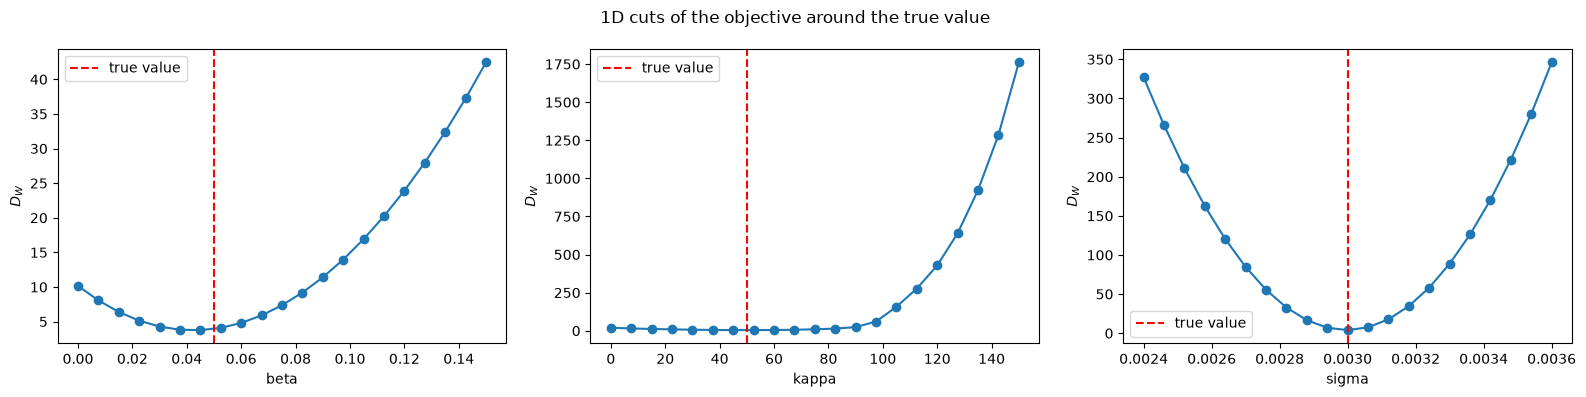

In [9]:
ranges = {
    "beta":  np.linspace(0, 3 * x_true[0], 21),
    "kappa": np.linspace(0, 3 * x_true[1], 21),
    "sigma": np.linspace(0.8 * x_true[2], 1.2 * x_true[2], 21),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for j, (name, values) in enumerate(ranges.items()):
    D = []
    for val in values:
        x = x_true.copy()
        x[j] = val                   # only parameter j moves
        D.append(gmm_objective(x, c_obs, W0))
    axes[j].plot(values, D, "o-")
    axes[j].axvline(x_true[j], color="red", ls="--", label="true value")
    axes[j].set_xlabel(name)
    axes[j].set_ylabel("$D_W$")
    axes[j].legend()
plt.suptitle("1D cuts of the objective around the true value")
plt.tight_layout()
plt.show()

## 2.3 Optimization

**Honest bounds**, chosen without knowing the true value: β ∈ [0, 0.5] (beyond, the model oscillates, Part 1), κ ∈ [0, 200] (explosion frontier, map 3), σ ∈ [0.5, 1.5] × the observed volatility.

**Nelder-Mead**: local, gradient-free. A simplex (4 points here) moves downhill by reflections, expansions and contractions. It needs a starting point `x0`, drawn at random within the bounds.

In [10]:
std_obs = c_obs[0]   # std of observed returns ≈ sigma
bounds = [(0, 0.5), (0, 200), (0.5 * std_obs, 1.5 * std_obs)]   # beta, kappa, sigma

rng_start = np.random.default_rng(123)
x0 = np.array([rng_start.uniform(a, b) for a, b in bounds])

res_nm = minimize(gmm_objective, x0=x0, args=(c_obs, W0), method="Nelder-Mead",
                  bounds=bounds, options={"maxfev": 300, "xatol": 1e-7})

print("θ̂     :", res_nm.x)
print("θ true:", x_true)
print("D_W   :", res_nm.fun, "| evaluations:", res_nm.nfev, "|", res_nm.message)

θ̂     : [0.00000000e+00 1.54055334e+01 3.00620726e-03]
θ true: [5.e-02 5.e+01 3.e-03]
D_W   : 2.6379293755890023 | evaluations: 226 | Optimization terminated successfully.


**DIRECT** (*DIviding RECTangles*): **global**, deterministic, no starting point. It splits the bounding box into rectangles, evaluates their centres and subdivides the "promising" ones (large or low-valued) first. Same budget as Nelder-Mead.

In [11]:
res_direct = direct(gmm_objective, bounds, args=(c_obs, W0), maxfun=300, maxiter=1000, locally_biased=False,
                    eps=1e-4, vol_tol=1e-16, len_tol=1e-6)
print("θ̂     :", res_direct.x)
print("θ true:", x_true)
print("D_W   :", res_direct.fun, "| evaluations:", res_direct.nfev, "|", res_direct.message)

θ̂     : [3.08641975e-03 1.76954733e+01 3.00871382e-03]
θ true: [5.e-02 5.e+01 3.e-03]
D_W   : 2.677671912784228 | evaluations: 333 | Number of function evaluations done is larger than maxfun=300


**2D cut (β, κ)**, σ at its true value. It shows what the 1D cuts hide: a **diagonal valley** along c − g = constant (white), where β and κ compensate each other. Both optimizers land at the bottom of the valley, not necessarily at the true value (star).

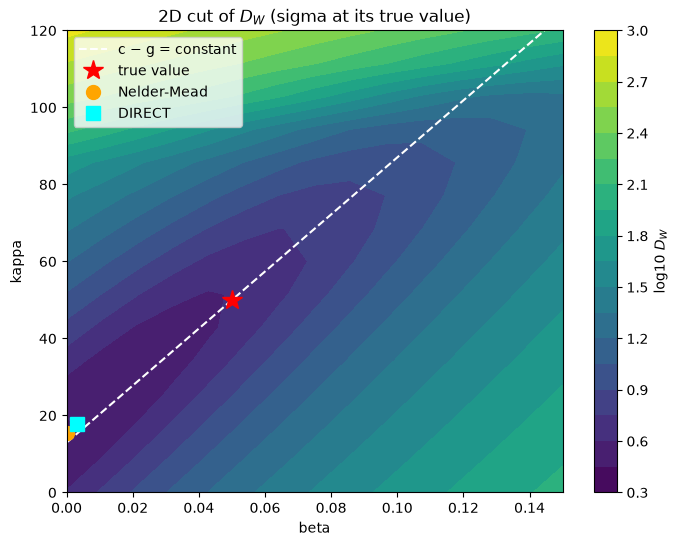

In [12]:
betas_2d = np.linspace(0, 0.15, 15)
kappas_2d = np.linspace(0, 120, 15)
D2 = np.array([[gmm_objective(np.array([b, k, x_true[2]]), c_obs, W0) for b in betas_2d]
               for k in kappas_2d])

# Line c - g = constant through the true θ (c = beta·gamma·alpha, g = 3·kappa·sigma²/(2·lam))
th = THETA_TRUE
slope = 3 * x_true[2] ** 2 / (2 * th["lam"]) / (th["gamma"] * th["alpha"])
beta_valley = x_true[0] + slope * (kappas_2d - x_true[1])

plt.figure(figsize=(8, 6))
plt.contourf(betas_2d, kappas_2d, np.log10(D2), levels=20)
plt.colorbar(label="log10 $D_W$")
plt.plot(beta_valley, kappas_2d, "w--", label="c − g = constant")
plt.plot(x_true[0], x_true[1], "r*", markersize=15, label="true value")
plt.plot(res_nm.x[0], res_nm.x[1], "o", color="orange", markersize=10, label="Nelder-Mead")
plt.plot(res_direct.x[0], res_direct.x[1], "s", color="cyan", markersize=10, label="DIRECT")
plt.xlim(betas_2d[0], betas_2d[-1])
plt.xlabel("beta")
plt.ylabel("kappa")
plt.title("2D cut of $D_W$ (sigma at its true value)")
plt.legend()
plt.savefig("../figures/gmm_valley.png", dpi=150, bbox_inches="tight")  # README figure
plt.show()

## 2.4 Optimal weighting matrix (Hansen)

**Hansen (1982).** The most efficient GMM uses $W^* = V^{-1}$, with V the **covariance** of the moments at the true θ. Unlike $W_0$, it accounts for correlations between moments (e.g. `acf1` and `acf2`), which would otherwise count twice.

**Iterative procedure**, since V depends on the unknown θ: start from the $W_0$ estimate (DIRECT); estimate V from 200 simulations at the current θ and set $W = V^{-1}$; re-optimize; stop when θ moves by less than 1 % of the bound widths (at most 5 iterations).

**Factor (1 + 1/N).** g combines the data noise (one series, variance V) and the model noise (mean of N = 10 series, V/10): Var(g) = V(1 + 1/N). It does not move the minimum, only the value of D_W (needed for the J-test).

In [13]:
# hansen_matrix (W* = V⁻¹, corrected by 1 + 1/N) is defined in abm.py
widths = np.array([b - a for a, b in bounds])

theta_list = [res_direct.x]   # θ⁽⁰⁾, obtained with W0
W_list = [W0]
for n in range(5):            # at most 5 iterations
    W = hansen_matrix(theta_list[-1])
    res = direct(gmm_objective, bounds, args=(c_obs, W), maxfun=800, locally_biased=False)
    theta_list.append(res.x)
    W_list.append(W)

    change = np.max(np.abs(theta_list[-1] - theta_list[-2]) / widths)  # relative to the bound widths
    print(f"iteration {n+1}: θ = {res.x}, D_W = {res.fun:.3f}, change = {change:.3%}")
    if change < 0.01:
        break

theta_star, W_star = theta_list[-1], W_list[-1]

iteration 1: θ = [1.14311843e-04 1.56835848e+01 3.01282409e-03], D_W = 2.417, change = 1.006%
iteration 2: θ = [1.14311843e-04 1.56835848e+01 3.01282409e-03], D_W = 2.417, change = 0.000%


**Hansen's J-test.** 4 moments for 3 parameters: the model cannot match them exactly. If the model is true, the remaining D_W is pure noise and follows χ²(4 − 3 = 1). p < 0.05 rejects the model.

In [14]:
D_min = gmm_objective(theta_star, c_obs, W_star)
print("D_W =", D_min, "| J-test p-value:", chi2.sf(D_min, df=4 - 3))

D_W = 2.416877699367821 | J-test p-value: 0.12003396460644615


The model is not rejected — as expected, since the data come from it. On the S&P 500, the same test would formally answer "is the model realistic?".

## 3.2 Speeding up with numba

The Monte Carlo of 2.5 needs hundreds of thousands of simulations: in pure Python (≈ 44 ms each) it would take hours. **numba** compiles the simulator loop to machine code on first call (`@njit`), making it ≈ 90 times faster with exactly the same path (the noise is drawn outside the compiled kernel, with the same generator). This is not parallelism: each simulation runs on one core, just faster.

In [15]:
import inspect

from abm import _chiarella_kernel, chiarella_fast

print(inspect.getsource(_chiarella_kernel.py_func))

@njit
def _chiarella_kernel(beta, kappa, gamma, alpha, lam, eps):
    """Same loop as chiarella, compiled to machine code by numba. The noise eps is drawn outside."""
    n = len(eps)
    p, m, v = np.zeros(n), np.zeros(n), np.zeros(n)
    for t in range(1, n):
        m[t] = (1 - alpha) * m[t - 1] + alpha * (p[t] - p[t - 1])
        v[t] = (1 - lam) * v[t - 1] + lam * p[t]
        if t == n - 1:
            break
        fundamentalists = kappa * ((v[t] - p[t]) ** 3 - (v[t - 1] - p[t - 1]) ** 3)
        chartists = beta * (np.tanh(gamma * m[t]) - np.tanh(gamma * m[t - 1]))
        p[t + 1] = p[t] + fundamentalists + chartists + eps[t + 1]
        if not np.isfinite(p[t + 1]) or abs(p[t + 1]) > 1e3:  # explosion
            p[t + 1:] = np.nan
            m[t + 1:] = np.nan
            v[t + 1:] = np.nan
            break
    return p, m, v



In [16]:
import time

p_slow, _, _ = chiarella(**theta_active, T=5000, rng=np.random.default_rng(0))
p_fast, _, _ = chiarella_fast(**theta_active, T=5000, rng=np.random.default_rng(0))
print("Identical paths:", np.allclose(p_slow, p_fast, rtol=0, atol=1e-12))

t0 = time.perf_counter()
for s in range(20):
    chiarella(**theta_active, T=5000, rng=np.random.default_rng(s))
t_slow = (time.perf_counter() - t0) / 20

t0 = time.perf_counter()
for s in range(200):
    chiarella_fast(**theta_active, T=5000, rng=np.random.default_rng(s))
t_fast = (time.perf_counter() - t0) / 200

print(f"Python: {t_slow*1e3:.1f} ms | numba: {t_fast*1e3:.2f} ms | speed-up: x{t_slow/t_fast:.0f}")

Identical paths: True
Python: 60.8 ms | numba: 0.47 ms | speed-up: x129


In `abm.py`, `get_moments_2` already uses `chiarella_fast`, so `model_moments`, `gmm_objective` and `hansen_matrix` benefit without any change.

## 2.5 Monte Carlo of the estimator (50 series, in parallel)

One fake market says little: the estimate depends on that series' noise. I generate **50 independent series** at the same true θ and calibrate each (DIRECT then Nelder-Mead, with W*). The spread of the 50 estimates is the **real precision** of the estimator. The calibrations are independent, so `joblib.Parallel` spreads them over all CPU cores.

In [17]:
# estimate (DIRECT then Nelder-Mead) is defined in abm.py
from joblib import Parallel, delayed

N_MC = 50
DATA_SEEDS = range(10000, 10000 + N_MC)
c_obs_mc = np.array([get_moments_2(THETA_TRUE, s) for s in DATA_SEEDS])   # (50, 4)

t0 = time.perf_counter()
outputs = Parallel(n_jobs=-1)(delayed(estimate)(c, W_star, 3000, 1000) for c in c_obs_mc)
print(f"Monte Carlo: {time.perf_counter() - t0:.0f} s")

estimates = np.array([x for x, _ in outputs])   # (50, 3)
D_min = np.array([d for _, d in outputs])       # (50,)

Monte Carlo: 131 s


**Precision per parameter**: bias, standard deviation, RMSE and RMSE relative to the true value.

In [18]:
errors = estimates - x_true
pd.DataFrame({
    "true value": x_true,
    "mean θ̂": estimates.mean(axis=0),
    "bias": errors.mean(axis=0),
    "std": estimates.std(axis=0),
    "RMSE": np.sqrt((errors**2).mean(axis=0)),
    "relative RMSE (%)": 100 * np.sqrt((errors**2).mean(axis=0)) / x_true,
}, index=ESTIMATED_PARAMS).round(5)

,true value,mean θ̂,bias,std,RMSE,relative RMSE (%)
beta,0.050,0.02875,-0.02125,0.02908,0.03602,72.04218
kappa,50.000,31.77457,-18.22543,24.46722,30.50919,61.01839
sigma,0.003,0.00301,0.00001,0.00004,0.00004,1.30270


**What to look at**: the spread of each parameter (top); the (β, κ) estimates lining up along the c − g = constant valley predicted by the Jacobian (bottom left); the precision of c − g itself (bottom middle); the J-test p-values, which should be uniform if the test is well calibrated (bottom right).

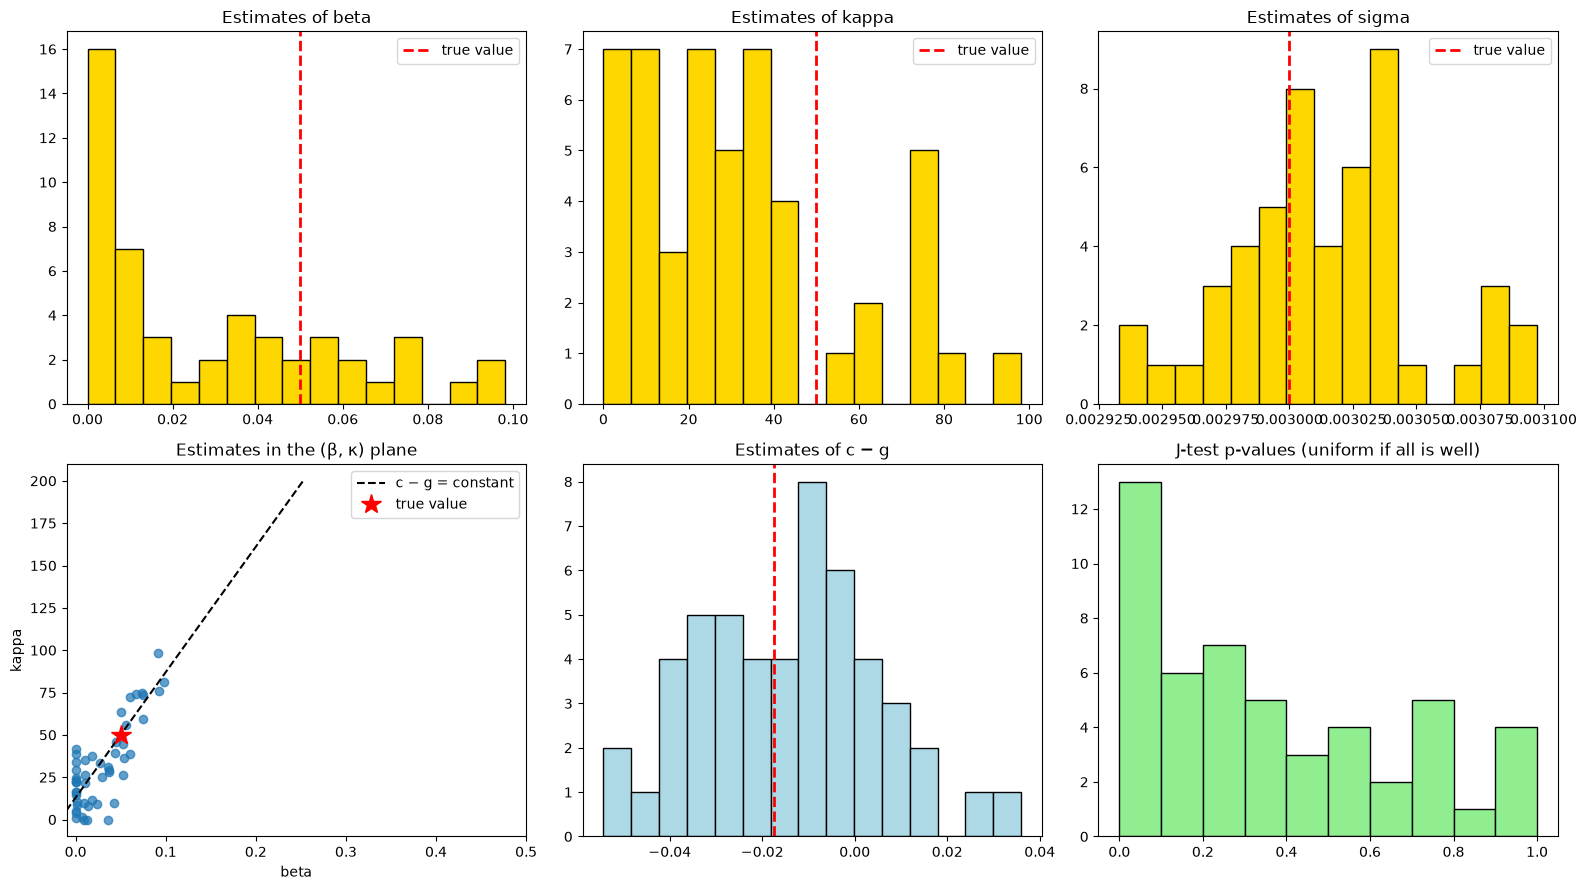

In [19]:
def c_minus_g(x, th=THETA_TRUE):
    beta, kappa, sigma = x[..., 0], x[..., 1], x[..., 2]
    return beta * th["gamma"] * th["alpha"] - 3 * kappa * sigma**2 / (2 * th["lam"])


fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for j, name in enumerate(ESTIMATED_PARAMS):   # row 1: histogram of each parameter
    axes[0, j].hist(estimates[:, j], bins=15, color="gold", edgecolor="k")
    axes[0, j].axvline(x_true[j], color="red", ls="--", lw=2, label="true value")
    axes[0, j].set_title(f"Estimates of {name}")
    axes[0, j].legend()

ax = axes[1, 0]   # (beta, kappa) cloud + line c - g = constant
ax.scatter(estimates[:, 0], estimates[:, 1], alpha=0.7)
k = np.linspace(0, 200, 50)
ax.plot(x_true[0] + slope * (k - x_true[1]), k, "k--", label="c − g = constant")
ax.plot(x_true[0], x_true[1], "r*", markersize=15, label="true value")
ax.set_xlim(-0.01, 0.5)
ax.set_xlabel("beta")
ax.set_ylabel("kappa")
ax.set_title("Estimates in the (β, κ) plane")
ax.legend()

ax = axes[1, 1]   # is the combination c - g well estimated?
ax.hist(c_minus_g(estimates), bins=15, color="lightblue", edgecolor="k")
ax.axvline(c_minus_g(x_true), color="red", ls="--", lw=2)
ax.set_title("Estimates of c − g")

ax = axes[1, 2]   # J-test: uniform p-values if W* is right
ax.hist(chi2.sf(D_min, df=4 - 3), bins=10, range=(0, 1), color="lightgreen", edgecolor="k")
ax.set_title("J-test p-values (uniform if all is well)")

plt.tight_layout()
plt.savefig("../figures/gmm_monte_carlo.png", dpi=150, bbox_inches="tight")  # README figure
plt.show()

## Conclusion of Part 2

**Approach.** Moments chosen by sensitivity analysis (normalized Jacobian + SVD); (β, κ, σ) estimated with 4 moments; E-GMM objective (10 fixed seeds), $W_0$ then Hansen's $W^*$; DIRECT then Nelder-Mead with honest bounds; Monte Carlo over 50 series (numba ×90, joblib).

**Results (relative RMSE over 50 series)**

| Parameter | True value | Budget 300 + 100 | Budget 3000 + 1000 |
|---|---|---|---|
| σ | 0.003 | 1.3 % | 1.3 % |
| β | 0.05 | 71 % | 72 % |
| κ | 50 | 60 % | 61 % |

- **σ is well identified**: the return volatility pins it down.
- **β and κ are not separately identifiable.** Chartists act through $c = \beta\gamma\alpha$, fundamentalists through $g = 3\kappa\sigma^2/(2\lambda)$, and the lag-1 ACF only sees $c - g$: the estimates line up along c − g = constant, as predicted by the Jacobian before any optimization.
- **Even c − g is poorly estimated**: its uncertainty (std ≈ 0.020) is as large as its value (−0.018). Enough precision would take ≈ 110 years of daily data; separating c from g, ≈ 3,500 years.
- **β and γ are exactly degenerate** in the linear regime, whatever the moments.
- **Downward bias** on β and κ: about 15 of 50 estimates hit the bound β = 0, at the end of the flat valley.
- **Robustness**: 10× the optimization budget changes nothing (5× the run time). The imprecision comes from the data, not the optimizer.
- **The J-test is miscalibrated**: ≈ 16 % rejections at 5 % while the model is true, mainly due to boundary estimates. On real data, D_W should be compared with its simulated distribution rather than the χ².

> **Main message.** The model has 6 parameters, but a price series only carries about two usable combinations: volatility, and the gap between momentum and mean reversion. Moment-based calibration cannot separate the agents' behaviours even when the model is true. This is a limit of the information in the data (*sloppiness*), not of the optimizer.

**Next.** The GMM compresses each series into 4 statistics. Part 3 replaces the simulator with a neural network; Part 4 uses every time step instead of summary statistics.